In [6]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

df = pd.read_csv('/content/dataset_sptrans_processado.csv')


colunas_remover = [
    'route_id',
    'route_short_name',
    'route_long_name',
    'Grupo'
]

X = df.drop(
    columns=colunas_remover,
    errors='ignore'
)


X = X.apply(pd.to_numeric, errors='coerce')


X = X.replace([np.inf, -np.inf], np.nan)


X = X.dropna(axis=1, how='all')


X = X.loc[:, X.isnull().mean() <= 0.5]


X = X.loc[:, X.nunique(dropna=True) > 1]


X = X.dropna(how='all')


X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)


imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

pca = PCA(n_components=2, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)


kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_train_pca)

# Identificar os grupos
grupos_treino = kmeans.labels_
grupos_teste = kmeans.predict(X_test_pca)

# Exibir resultados
print('Quantidade de registros:', len(X))
print('Quantidade de variáveis:', X.shape[1])

print('\nDivisão dos dados:')
print('Treino:', len(X_train))
print('Teste:', len(X_test))

print('\nVariância explicada pelo PCA:')
print(pca.explained_variance_ratio_)
print('Variância acumulada:',
      pca.explained_variance_ratio_.sum())

print('\nDistribuição dos grupos no treino:')
print(pd.Series(grupos_treino).value_counts().sort_index())

print('\nDistribuição dos grupos no teste:')
print(pd.Series(grupos_teste).value_counts().sort_index())


Quantidade de registros: 1309
Quantidade de variáveis: 14

Divisão dos dados:
Treino: 1047
Teste: 262

Variância explicada pelo PCA:
[0.43912692 0.31591212]
Variância acumulada: 0.7550390426232796

Distribuição dos grupos no treino:
0    332
1    234
2    481
Name: count, dtype: int64

Distribuição dos grupos no teste:
0     84
1     61
2    117
Name: count, dtype: int64


In [7]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, ParameterGrid
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

df = pd.read_csv('/content/dataset_sptrans_processado.csv')

colunas_remover = [
    'route_id',
    'route_short_name',
    'route_long_name',
    'Grupo'
]

X = df.drop(columns=colunas_remover, errors='ignore')


X = X.apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan)


X = X.dropna(axis=1, how='all')
X = X.loc[:, X.nunique(dropna=True) > 1]


X = X.dropna(how='all')


X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)


cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


parametros = {
    'kmeans__n_clusters': [2, 3, 4],
    'kmeans__init': ['k-means++', 'random'],
    'kmeans__n_init': [10, 20]
}

combinacoes = list(ParameterGrid(parametros))

resultados = []

for params in combinacoes:

    metricas = []

    for idx_train, idx_val in cv.split(X_train):

        treino_fold = X_train.iloc[idx_train]
        validacao_fold = X_train.iloc[idx_val]

        modelo = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=2)),
            ('kmeans', KMeans(
                random_state=42,
                **{
                    chave.replace('kmeans__', ''): valor
                    for chave, valor in params.items()
                }
            ))
        ])

        modelo.fit(treino_fold)


        X_val_pca = modelo[:-1].transform(validacao_fold)

        grupos = modelo.named_steps['kmeans'].predict(X_val_pca)


        if len(np.unique(grupos)) < 2:
            continue

        silhouette = silhouette_score(X_val_pca, grupos)
        davies = davies_bouldin_score(X_val_pca, grupos)
        calinski = calinski_harabasz_score(X_val_pca, grupos)

        metricas.append([
            silhouette,
            davies,
            calinski
        ])

    if metricas:
        metricas = np.array(metricas)

        resultados.append({
            'n_clusters': params['kmeans__n_clusters'],
            'init': params['kmeans__init'],
            'n_init': params['kmeans__n_init'],
            'Silhouette': metricas[:, 0].mean(),
            'Davies-Bouldin': metricas[:, 1].mean(),
            'Calinski-Harabasz': metricas[:, 2].mean()
        })

resultados_df = pd.DataFrame(resultados)

resultados_df = resultados_df.sort_values(
    by='Silhouette',
    ascending=False
).reset_index(drop=True)

print('RESULTADOS DA VALIDAÇÃO CRUZADA')
print(resultados_df.round(4).to_string(index=False))

print('\nQuantidade de combinações avaliadas:', len(resultados_df))

melhor = resultados_df.iloc[0]

print('\nMELHORES HIPERPARÂMETROS')
print(melhor)

modelo_final = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('kmeans', KMeans(
        n_clusters=int(melhor['n_clusters']),
        init=melhor['init'],
        n_init=int(melhor['n_init']),
        random_state=42
    ))
])

modelo_final.fit(X_train)

X_test_pca = modelo_final[:-1].transform(X_test)

grupos_teste = modelo_final.named_steps['kmeans'].predict(
    X_test_pca
)

silhouette_teste = silhouette_score(
    X_test_pca, grupos_teste
)

davies_teste = davies_bouldin_score(
    X_test_pca, grupos_teste
)

calinski_teste = calinski_harabasz_score(
    X_test_pca, grupos_teste
)

print('\nAVALIAÇÃO FINAL NO CONJUNTO DE TESTE')
print('Silhouette Score:', round(silhouette_teste, 4))
print('Davies-Bouldin:', round(davies_teste, 4))
print('Calinski-Harabasz:', round(calinski_teste, 4))

print('\nDistribuição dos grupos no teste:')
print(pd.Series(grupos_teste).value_counts().sort_index())

print('\nVariância explicada pelo PCA:')
print(
    modelo_final.named_steps['pca'].explained_variance_ratio_
)

print(
    'Variância acumulada:',
    modelo_final.named_steps['pca'].explained_variance_ratio_.sum()
)


RESULTADOS DA VALIDAÇÃO CRUZADA
 n_clusters      init  n_init  Silhouette  Davies-Bouldin  Calinski-Harabasz
          4 k-means++      20      0.4423          0.7694           204.8089
          4    random      10      0.4423          0.7694           204.8089
          4 k-means++      10      0.4423          0.7694           204.8089
          4    random      20      0.4421          0.7696           204.7397
          2    random      20      0.4413          1.0364           143.2004
          2    random      10      0.4413          1.0364           143.2004
          2 k-means++      20      0.4413          1.0364           143.2004
          2 k-means++      10      0.4413          1.0364           143.2004
          3 k-means++      10      0.3919          0.8297           162.8471
          3 k-means++      20      0.3914          0.8306           162.6228
          3    random      10      0.3905          0.8307           162.3030
          3    random      20      0.3902   

COMPARAÇÃO DAS MÉTRICAS


,Métrica,Treino (CV),Teste
0,Silhouette,0.4423,0.4537
1,Davies-Bouldin,0.7694,0.7265
2,Calinski-Harabasz,204.8089,290.3248


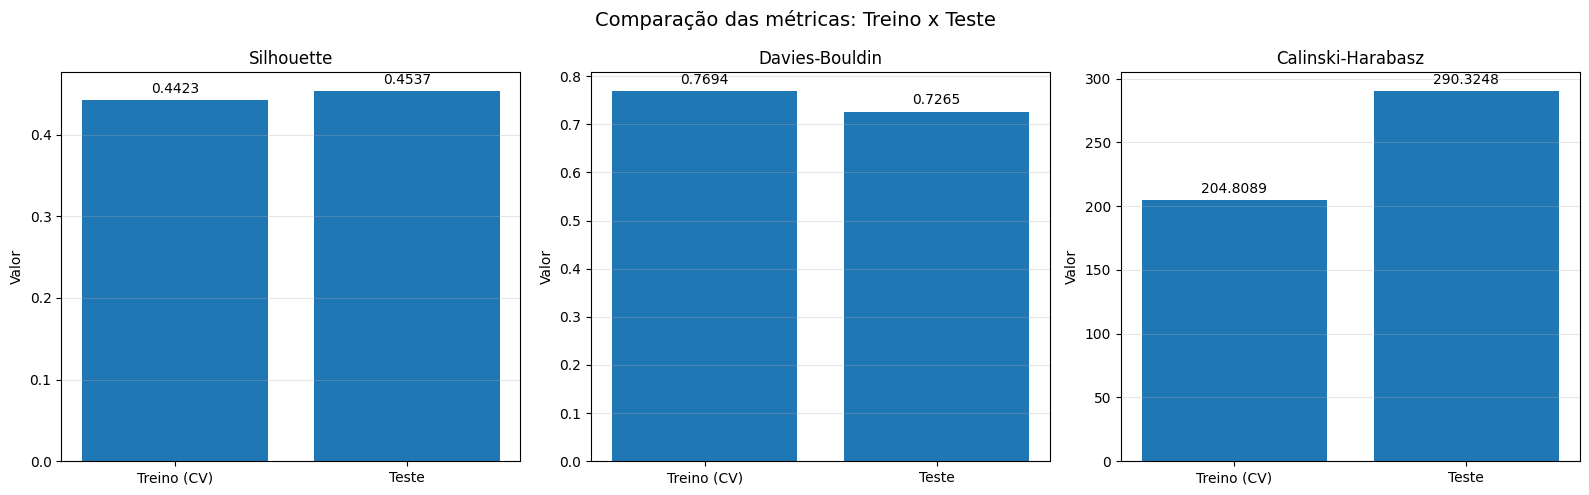


ANÁLISE DE OVERFITTING
Não foram identificados sinais evidentes de overfitting.
O desempenho do modelo permaneceu consistente no teste.

CONCLUSÃO PARA O CIDADÃO

O modelo identificou quatro grupos de linhas de ônibus com
características operacionais semelhantes.

Essa análise pode ajudar a identificar padrões na rede de
transporte público, apoiar o planejamento das linhas e contribuir
para futuras melhorias na distribuição e organização do serviço.

O modelo não prevê atrasos, mas oferece informações que podem
auxiliar decisões para melhorar o transporte oferecido à população.



In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Métricas da validação cruzada e do teste
metricas = pd.DataFrame({
    'Métrica': ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz'],
    'Treino (CV)': [0.4423, 0.7694, 204.8089],
    'Teste': [0.4537, 0.7265, 290.3248]
})

print("COMPARAÇÃO DAS MÉTRICAS")
display(metricas.round(4))

# Gráficos comparativos
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metricas_graficos = [
    ('Silhouette', 0),
    ('Davies-Bouldin', 1),
    ('Calinski-Harabasz', 2)
]

for ax, (nome, indice) in zip(axes, metricas_graficos):
    valores = metricas.iloc[indice, 1:3].values

    barras = ax.bar(
        ['Treino (CV)', 'Teste'],
        valores
    )

    ax.set_title(nome)
    ax.set_ylabel('Valor')
    ax.bar_label(barras, fmt='%.4f', padding=3)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Comparação das métricas: Treino x Teste', fontsize=14)
plt.tight_layout()
plt.show()

# Análise de overfitting
print("\nANÁLISE DE OVERFITTING")

silhouette_diff = abs(0.4537 - 0.4423)
db_diff = abs(0.7265 - 0.7694)

if silhouette_diff < 0.05 and db_diff < 0.1:
    print("Não foram identificados sinais evidentes de overfitting.")
    print("O desempenho do modelo permaneceu consistente no teste.")
else:
    print("Existem diferenças entre treino e teste que merecem investigação.")

# Conclusão para o cidadão
print("\nCONCLUSÃO PARA O CIDADÃO")
print("""
O modelo identificou quatro grupos de linhas de ônibus com
características operacionais semelhantes.

Essa análise pode ajudar a identificar padrões na rede de
transporte público, apoiar o planejamento das linhas e contribuir
para futuras melhorias na distribuição e organização do serviço.

O modelo não prevê atrasos, mas oferece informações que podem
auxiliar decisões para melhorar o transporte oferecido à população.
""")


### Fonte, link e período dos dados

Os dados utilizados no projeto MoveSmart foram obtidos por meio da SPTrans (São Paulo Transporte), responsável pela gestão do transporte público por ônibus do município de São Paulo.

Foi utilizado o conjunto de dados GTFS (General Transit Feed Specification), disponibilizado na área de desenvolvedores da SPTrans. Esse formato fornece informações estruturadas sobre linhas, viagens, pontos de parada, horários, frequências e trajetos do transporte público.

- **Fonte:** SPTrans – Área do Desenvolvedor.
- **Link:** https://www.sptrans.com.br/desenvolvedores/
- **Dataset:** GTFS.
- **Localização:** Município de São Paulo – SP.
- **Período de referência da versão consultada:** 01/10/2023 a 01/06/2027.
- **Data de consulta:** 11/11/2026.

Os arquivos foram processados e utilizados para construir um conjunto de características operacionais das linhas de ônibus, posteriormente aplicado ao algoritmo K-Means para identificar grupos com padrões semelhantes.